<center>
    
# Statistical Inference and Simulation of Airborne Chemical Emissions
## Author: Aidan Arnold
## Instructor: Masoud Yari
## DSCI 431

</center>

## 1.
### Imports and Data Cleaning
Imports UCI Air Quality dataset. The data was collected in a heavily polluted Italian city from March 2004 to April 2005. Clean empty rows, columns, and -200 placeholder values with NaN. Preview of data shape and head.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',') # move to downloads
print('Starting Dataset Shape: ',df.shape)

df = df.dropna(how='all', axis=0)
df = df.dropna(how='all', axis=1)
df = df.replace(to_replace=-200, value=np.nan)

print('Cleaned Dataset Shape: ',df.shape)
display(df.head())
display(df[['Date', 'Time', 'CO(GT)', 'NOx(GT)']].head())


Starting Dataset Shape:  (9471, 17)
Cleaned Dataset Shape:  (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


,Date,Time,CO(GT),NOx(GT)
0,10/03/2004,18.00.00,2.6,166.0
1,10/03/2004,19.00.00,2.0,103.0
2,10/03/2004,20.00.00,2.2,131.0
3,10/03/2004,21.00.00,2.2,172.0
4,10/03/2004,22.00.00,1.6,131.0


## 2.
### Exploratory Data Analysis
#### Dataset Shape Visualization
Computes summary statistics. Histograms for CO(GT) and NOx(GT) data. Displays mean, median, and skewness.

,CO(GT),NOx(GT)
count,7674.000000,7718.000000
mean,2.152750,246.896735
std,1.453252,212.979168
min,0.100000,2.000000
25%,1.100000,98.000000
50%,1.800000,180.000000
75%,2.900000,326.000000
max,11.900000,1479.000000


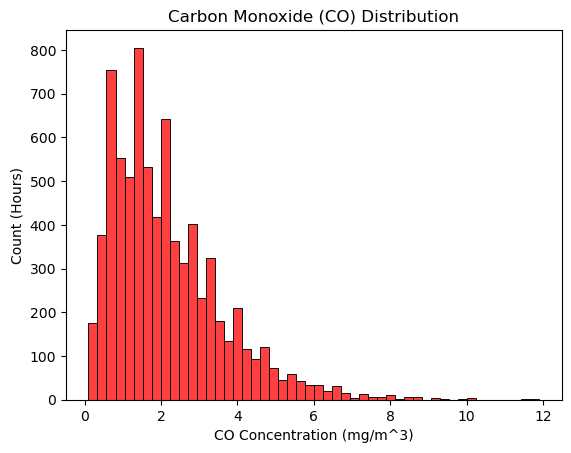

CO Mean: 2.15 | CO Median: 1.80 | CO Skewness: 1.37


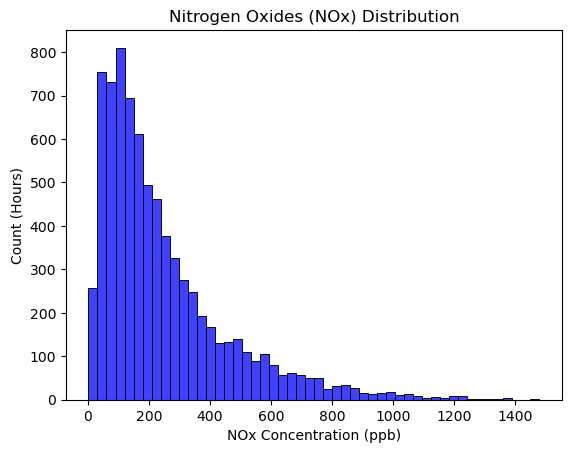

NOx Mean: 246.90 | NOx Median: 180.00 | NOx Skewness: 1.72


In [5]:
display(df[['CO(GT)', 'NOx(GT)']].describe())

co_colm_clean = df['CO(GT)'].dropna()
nox_colm_clean = df['NOx(GT)'].dropna()

bins_co = int(((np.sqrt(len(co_colm_clean))) + 1 + np.log2(len(co_colm_clean)))/2)
bins_nox = int(((np.sqrt(len(nox_colm_clean))) + 1 + np.log2(len(nox_colm_clean)))/2)

sns.histplot(co_colm_clean, bins=bins_co, color='red')
plt.title('Carbon Monoxide (CO) Distribution')
plt.xlabel('CO Concentration (mg/m^3)')
plt.ylabel('Count (Hours)')
plt.show()

print(f'CO Mean: {co_colm_clean.mean():.2f} | CO Median: {co_colm_clean.median():.2f} | CO Skewness: {co_colm_clean.skew():.2f}')

sns.histplot(nox_colm_clean, bins=bins_nox, color='blue')
plt.title('Nitrogen Oxides (NOx) Distribution')
plt.xlabel('NOx Concentration (ppb)')
plt.ylabel('Count (Hours)')
plt.show()

print(f'NOx Mean: {nox_colm_clean.mean():.2f} | NOx Median: {nox_colm_clean.median():.2f} | NOx Skewness: {nox_colm_clean.skew():.2f}')


#### ECDFs
Displays ECDFs for both pollutants with 25, 50, and 75 percentile vertical lines. 90, 95, and 99 percentiles are calculated.

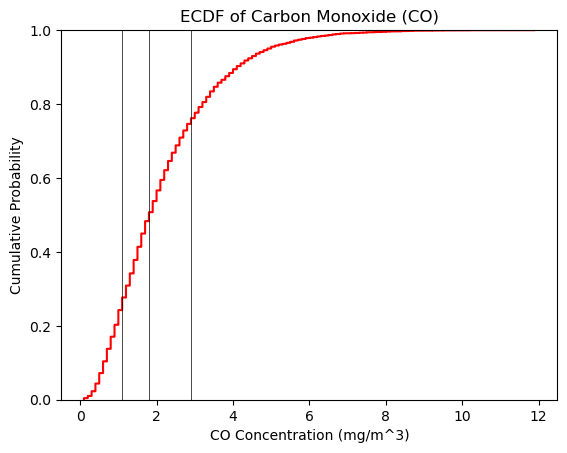

CO percentiles: 90: 4.1 | 95: 4.9 | 99: 6.8


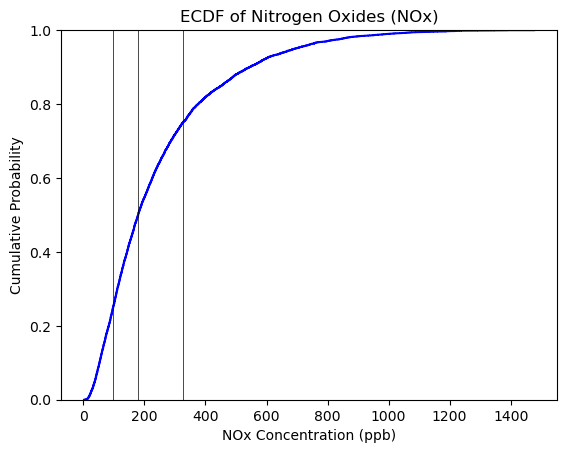

NOx percentiles: 90: 544.0 | 95: 693.0 | 99: 1000.8


In [8]:
co_percentiles = np.percentile(co_colm_clean, [25, 50, 75, 90, 95, 99])

sns.ecdfplot(co_colm_clean, color='red')
plt.axvline(co_percentiles[0], color='black', linewidth=0.5)
plt.axvline(co_percentiles[1], color='black', linewidth=0.5)
plt.axvline(co_percentiles[2], color='black', linewidth=0.5)
plt.title('ECDF of Carbon Monoxide (CO)')
plt.xlabel('CO Concentration (mg/m^3)')
plt.ylabel('Cumulative Probability')
plt.show()

print(f'CO percentiles: 90: {co_percentiles[3]} | 95: {co_percentiles[4]} | 99: {co_percentiles[5]}')

nox_percentiles = np.percentile(nox_colm_clean, [25, 50, 75, 90, 95, 99])

sns.ecdfplot(nox_colm_clean, color='blue')
plt.axvline(nox_percentiles[0], color='black', linewidth=0.5)
plt.axvline(nox_percentiles[1], color='black', linewidth=0.5)
plt.axvline(nox_percentiles[2], color='black', linewidth=0.5)
plt.title('ECDF of Nitrogen Oxides (NOx)')
plt.xlabel('NOx Concentration (ppb)')
plt.ylabel('Cumulative Probability')
plt.show()

print(f'NOx percentiles: 90: {nox_percentiles[3]} | 95: {nox_percentiles[4]} | 99: {nox_percentiles[5]:.1f}')


## 3.
### Statistical Approach
#### Hypothesis Testing
Prints t-statistic and p-value for hypothesis testing.

$H_{0,\text{CO}}$: CO concentration at 8AM = CO concentration at 2PM

$H_{a,\text{CO}}$: CO concentration at 8AM > CO concentration at 2PM

$H_{0,\text{NOx}}$: NOx concentration at 8AM = NOx concentration at 2PM

$H_{a,\text{NOx}}$: NOx concentration at 8AM > NOx concentration at 2PM

The null hypothesis was rejected for both cases. Average pollutant concentrations at both times were plotted in a bar chart for both pollutants.

CO t-stat: 6.47 | CO p-value 9.87e-11


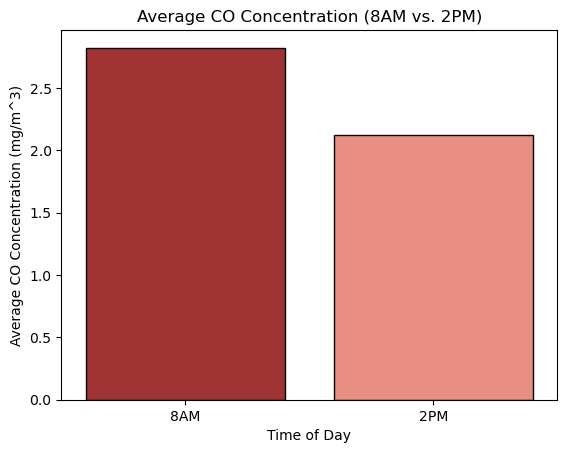

NOx t-stat: 6.24 | NOx p-value 4.01e-10


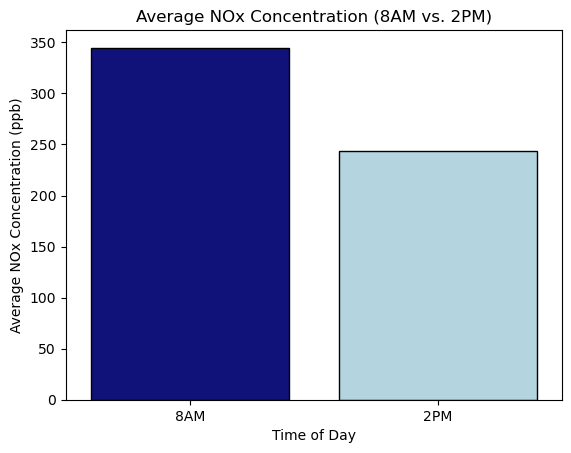

In [11]:
co_rush_hour = df[df['Time'] == '08.00.00']['CO(GT)'].dropna()
co_mid_day = df[df['Time'] == '14.00.00']['CO(GT)'].dropna()

co_t_stat, co_p_val = stats.ttest_ind(co_rush_hour, co_mid_day, equal_var=False, alternative='greater')
print(f'CO t-stat: {co_t_stat:.2f} | CO p-value {co_p_val:.3g}')

sns.barplot(x=['8AM', '2PM'], y=[co_rush_hour.mean(), co_mid_day.mean()],
            palette=['firebrick','salmon'], edgecolor='black', hue=['8AM', '2PM'])
plt.title('Average CO Concentration (8AM vs. 2PM)')
plt.xlabel('Time of Day')
plt.ylabel('Average CO Concentration (mg/m^3)')
plt.show()

nox_rush_hour = df[df['Time'] == '08.00.00']['NOx(GT)'].dropna()
nox_mid_day = df[df['Time'] == '14.00.00']['NOx(GT)'].dropna()

nox_t_stat, nox_p_val = stats.ttest_ind(nox_rush_hour, nox_mid_day, equal_var=False, alternative='greater')
print(f'NOx t-stat: {nox_t_stat:.2f} | NOx p-value {nox_p_val:.3g}')

sns.barplot(x=['8AM', '2PM'], y=[nox_rush_hour.mean(), nox_mid_day.mean()],
            palette=['darkblue','lightblue'], edgecolor='black', hue=['8AM', '2PM'])
plt.title('Average NOx Concentration (8AM vs. 2PM)')
plt.xlabel('Time of Day')
plt.ylabel('Average NOx Concentration (ppb)')
plt.show()


#### Bootstrap Sampling
Bootstrap sampling with 10000 iterations. Random seed is set to 42. 95% confidence intervals for the true population's mean are recorded for both pollutants. Bootstrap histograms are plotted with the confidence intervals marked. Bootstrapped means, standard error of means, and skewness are calculated.

CO confidence interval: [ 2.12, 2.19 ]
NOx confidence interval: [ 242.11, 251.67 ]


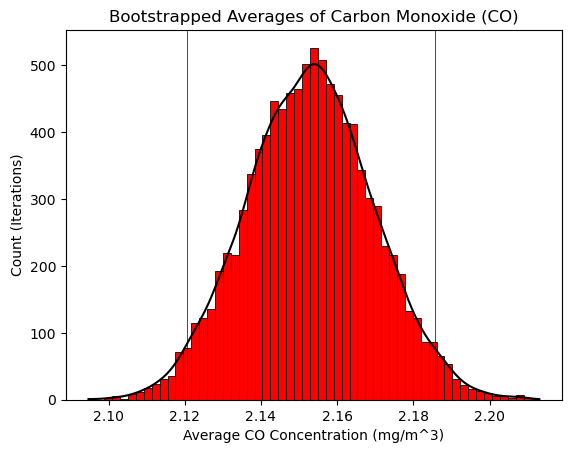

CO Bootstrapped Mean: 2.15 | Standard Error of the Mean: 0.02 | Skewness: 0.04


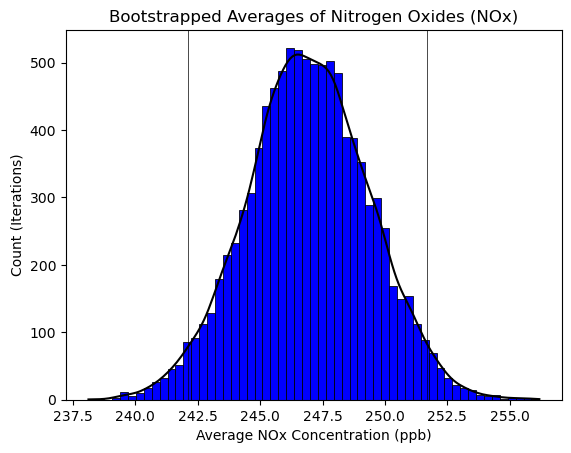

NOx Bootstrapped Mean: 246.93 | Standard Error of the Mean: 2.43 | Skewness: 0.01


In [14]:
np.random.seed(42)

co_iter = 10000
co_btstrp_avgs = []

for i in range(co_iter):
    co_sample = np.random.choice(co_colm_clean, size=len(co_colm_clean), replace=True)
    co_btstrp_avgs.append(np.mean(co_sample))

co_ci = np.percentile(co_btstrp_avgs, [2.5, 97.5])
print('CO confidence interval: [ %.2f, %.2f'% (co_ci[0], co_ci[1]),']')

nox_iter = 10000
nox_btstrp_avgs = []

for i in range(nox_iter):
    nox_sample = np.random.choice(nox_colm_clean, size=len(nox_colm_clean), replace=True)
    nox_btstrp_avgs.append(np.mean(nox_sample))

nox_ci = np.percentile(nox_btstrp_avgs, [2.5, 97.5])
print('NOx confidence interval: [ %.2f, %.2f'% (nox_ci[0], nox_ci[1]),']')

btstrp_bins = int((np.sqrt(10000) + 1 + np.log2(10000))/2)

sns.histplot(co_btstrp_avgs, bins=btstrp_bins, color='black', kde=True, facecolor='red')
plt.axvline(co_ci[0], color='black', linewidth=0.5)
plt.axvline(co_ci[1], color='black', linewidth=0.5)
plt.title('Bootstrapped Averages of Carbon Monoxide (CO)')
plt.xlabel('Average CO Concentration (mg/m^3)')
plt.ylabel('Count (Iterations)')
plt.show()

print(f'CO Bootstrapped Mean: {np.mean(co_btstrp_avgs):.2f} | Standard Error of the Mean: '
f'{np.std(co_btstrp_avgs):.2f} | Skewness: {stats.skew(co_btstrp_avgs):.2f}')

sns.histplot(nox_btstrp_avgs, bins=btstrp_bins, color='black', kde=True, facecolor='blue')
plt.axvline(nox_ci[0], color='black', linewidth=0.5)
plt.axvline(nox_ci[1], color='black', linewidth=0.5)
plt.title('Bootstrapped Averages of Nitrogen Oxides (NOx)')
plt.xlabel('Average NOx Concentration (ppb)')
plt.ylabel('Count (Iterations)')
plt.show()

print(f'NOx Bootstrapped Mean: {np.mean(nox_btstrp_avgs):.2f} | Standard Error of the Mean: ' 
f'{np.std(nox_btstrp_avgs):.2f} | Skewness: {stats.skew(nox_btstrp_avgs):.2f}')
